# PyNeuraLogic I-RAVEN solver

End to end: ResNet-18 perception → torch embeddings → PyNeuraLogic message passing and
scoring → torch softmax loss (`experiments/max_data_L2`). I-RAVEN test: **68.46%** end to end, 68.49%
with XML labels (epoch 126); earlier torch GNN: 68.81% (trained with the position bug).

The reasoner is defined inline and checked against `train_all_constellations.py` in §9; the trained
ResNet-18 is loaded from its checkpoint.

In [1]:
import os, sys, glob, shutil, tempfile, random, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
from collections import Counter
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageDraw
from IPython.display import display
import neuralogic
neuralogic.set_max_memory_size(30)
from neuralogic.logging import clear_handlers; clear_handlers()
from neuralogic.core import Model, R, V, Settings, Transformation, Aggregation, Metadata
from neuralogic.nn import Adam
from neuralogic.nn.torch_function import NeuraLogic

if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")   # paths below are relative to the repo root
for p in (".", "pynl", "torch_gnn", "frontend", "raven", "neuro-vector-symbolic-architectures"): sys.path.insert(0, os.path.abspath(p))
from train_pynl import parse, POS_MAP      # XML -> objects (ground truth, for checking perception and training)
from gnn_solver import load_frontend       # trained ResNet-18 + attribute codebook
DATA = "data/I-RAVEN-10000"
FRONTEND = "log/universal_frontend_correct_proportional_mean3"
CONSTELLATIONS = list(POS_MAP)
POS_LIST = {c: sorted(m.values()) for c, m in POS_MAP.items()}       # universal position ids per layout
torch.manual_seed(0); random.seed(0); torch.set_num_threads(16)

## 1. A puzzle: 8 context panels (3×3 minus the last) and 8 candidates, 160×160 grey images

RAVEN_1273_val.npz | distribute_four | (16, 160, 160) uint8 | answer: candidate 7


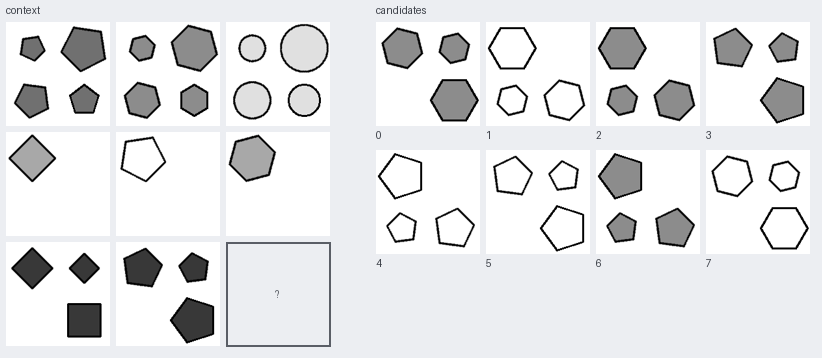

In [2]:
def show_puzzle(images, marks={}, s=104, g=6):
    W, H = 7 * s + 9 * g + 40, 3 * s + 4 * g + 22
    img = Image.new("RGB", (W, H), (236, 238, 242)); d = ImageDraw.Draw(img)
    d.text((g, 4), "context", fill=(60, 64, 72)); d.text((3 * s + 4 * g + 40, 4), "candidates", fill=(60, 64, 72))
    for p in range(9):
        x, y = g + p % 3 * (s + g), 22 + p // 3 * (s + g)
        if p < 8: img.paste(Image.fromarray(images[p]).resize((s, s)).convert("RGB"), (x, y))
        else: d.rectangle([x, y, x + s, y + s], outline=(90, 94, 102), width=2); d.text((x + s // 2 - 3, y + s // 2 - 6), "?", fill=(90, 94, 102))
    for c in range(8):
        x, y = 3 * s + 4 * g + 40 + c % 4 * (s + g), 22 + c // 4 * (s + 18 + g)
        img.paste(Image.fromarray(images[8 + c]).resize((s, s)).convert("RGB"), (x, y))
        rgb, label = marks.get(c, ((60, 64, 72), ""))
        if c in marks: d.rectangle([x - 3, y - 3, x + s + 2, y + s + 2], outline=rgb, width=4)
        d.text((x, y + s + 3), f"{c} {label}", fill=rgb)
    display(img)

CFG = "distribute_four"
f = sorted(glob.glob(f"{DATA}/{CFG}/*_val.npz"))[303]      # unseen (val 300+); picked as one it gets right, accuracy in §10
images, target = np.load(f)["image"], int(np.load(f)["target"])
print(os.path.basename(f), "|", CFG, "|", images.shape, images.dtype, "| answer: candidate", target)
show_puzzle(images)

## 2. Perception: ResNet-18 → cosine against a frozen attribute codebook → objects

In [3]:
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()) as log:              # silence the ImageNet-init message; trained weights load on top
    frontend, cos_layer, _, _ = load_frontend(FRONTEND, device="cpu")    # trained on RAVEN attribute labels
print(log.getvalue().strip().splitlines()[-1])
W = F.normalize(cos_layer.W.data)                                    # 22 positions x (300 type/size/colour rows + 1)
shapes = []
hooks = [m.register_forward_hook(lambda m, i, o, n=n: shapes.append((n, tuple(o.shape)))) for n, m in frontend.named_children()]
with torch.no_grad(): frontend(torch.tensor(images[:1], dtype=torch.float).unsqueeze(1))
for h in hooks: h.remove()
for n, sh in shapes: print(f"  {n:<8} -> {sh}")
print(f"ResNet-18 {sum(p.numel() for p in frontend.parameters()):,} weights | codebook {tuple(W.shape)}")

Loaded frontend: d=512, W=torch.Size([6622, 512]), epoch=198, acc=95.2625%


  conv1    -> (1, 64, 160, 160)
  bn1      -> (1, 64, 160, 160)
  relu     -> (1, 64, 160, 160)
  maxpool  -> (1, 64, 160, 160)
  layer1   -> (1, 64, 160, 160)
  layer2   -> (1, 128, 80, 80)
  layer3   -> (1, 256, 40, 40)
  layer4   -> (1, 512, 20, 20)
  avgpool  -> (1, 512, 1, 1)
  fc       -> (1, 512)
  Tanh     -> (1, 512)
ResNet-18 11,439,168 weights | codebook (6622, 512)


In [4]:
TAU = 0.23                                                    # an object exists if its best cosine clears this

def perceive(images, cfg):
    x = torch.tensor(images, dtype=torch.float).unsqueeze(1)
    with torch.no_grad():
        sims = F.linear(F.normalize(frontend(x)), W).view(16, 22, 301)[..., :300]
    best, idx = sims.max(-1)                                  # per panel and position: best attribute row
    panels = []
    for p in range(16):
        objs = []
        for q in POS_LIST[cfg]:
            k = int(idx[p, q])
            if best[p, q] > TAU:
                objs.append({"pos": q, "type": k % 5, "size": k % 30 // 5, "color": k // 30})
        panels.append(objs)
    return panels

key = lambda panel: sorted((o["pos"], o["type"], o["size"], o["color"]) for o in panel)
panels = perceive(images, CFG)
truth = parse(f.replace(".npz", ".xml"), CFG)
print("objects per panel:", [len(p) for p in panels])
print("context panel 0:", panels[0])
print("panels identical to the XML labels:", sum(key(a) == key(b) for a, b in zip(panels, truth)), "/ 16")

objects per panel: [4, 4, 4, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
context panel 0: [{'pos': 1, 'type': 2, 'size': 1, 'color': 5}, {'pos': 2, 'type': 2, 'size': 5, 'color': 5}, {'pos': 3, 'type': 2, 'size': 3, 'color': 5}, {'pos': 4, 'type': 2, 'size': 2, 'color': 5}]
panels identical to the XML labels: 16 / 16


## 3. Nodes: 16 panels × 9 slots, 5 ids per slot (from the perceived objects)

In [5]:
SLOTS = max(map(len, POS_LIST.values()))
NODES = [f"p{p}_s{s}" for p in range(16) for s in range(SLOTS)]       # p0-7 context, p8-15 candidates
ATTRS = [("pos", 22), ("col", 10), ("shp", 5), ("siz", 6), ("pnl", 9)]
for c in CONSTELLATIONS: print(f"{c:<40} {len(POS_LIST[c])} slots, position ids {POS_LIST[c]}")
print(len(NODES), "nodes")

center_single                            1 slots, position ids [0]
distribute_four                          4 slots, position ids [1, 2, 3, 4]
distribute_nine                          9 slots, position ids [5, 6, 7, 8, 9, 10, 11, 12, 13]
left_center_single_right_center_single   2 slots, position ids [14, 15]
up_center_single_down_center_single      2 slots, position ids [16, 17]
in_center_single_out_center_single       2 slots, position ids [0, 9]
in_distribute_four_out_center_single     5 slots, position ids [0, 18, 19, 20, 21]
144 nodes


In [6]:
def encode_puzzle(panels, cfg):
    idx = {pos: k for k, pos in enumerate(POS_LIST[cfg])}
    attrs = torch.zeros(16 * SLOTS, 5, dtype=torch.long)
    active = torch.zeros(16 * SLOTS, dtype=torch.bool)
    for p in range(16):
        for o in panels[p]:
            i = p * SLOTS + idx[o["pos"]]
            attrs[i] = torch.tensor([o["pos"], o["color"], o["type"], o["size"], min(p, 8)])   # every candidate: panel 8
            active[i] = True
    return attrs, active

attrs, active = encode_puzzle(panels, CFG)
for p in (0, 8 + target):
    print(f"panel {p:>2}:", [attrs[p * SLOTS + k].tolist() if active[p * SLOTS + k] else "-" for k in range(SLOTS)])

panel  0: [[1, 5, 2, 1, 0], [2, 5, 2, 5, 0], [3, 5, 2, 3, 0], [4, 5, 2, 2, 0], '-', '-', '-', '-', '-']
panel 15: [[1, 0, 3, 4, 8], [2, 0, 3, 2, 8], '-', [4, 0, 3, 5, 8], '-', '-', '-', '-', '-']


## 4. Edges: same slot across panels (no edges inside a panel, none between candidates)

In [7]:
EDGE_TYPES = ["same_panel", "ctx_ctx", "ctx_cand", "cand_ctx"]      # same_panel unused (--no-same-panel)

def edges():
    e = []
    for s in range(SLOTS):
        for i in range(8):
            e += [(f"p{i}_s{s}", f"p{j}_s{s}", "ctx_ctx") for j in range(8) if j != i]
            for c in range(8, 16):
                e += [(f"p{i}_s{s}", f"p{c}_s{s}", "ctx_cand"), (f"p{c}_s{s}", f"p{i}_s{s}", "cand_ctx")]
    return e

def structural_facts():
    f = [R.edge(s, t, r) for s, t, r in edges()]
    f += [R.is_context(f"p{p}_s{s}") for p in range(8) for s in range(SLOTS)]
    f += [R.in_cand(f"p{8 + c}_s{s}", f"c{c}") for c in range(8) for s in range(SLOTS)]
    return f

print(len(edges()), "edges:", dict(Counter(r for *_, r in edges())))
print(edges()[0], edges()[7])

1656 edges: {'ctx_ctx': 504, 'ctx_cand': 576, 'cand_ctx': 576}
('p0_s0', 'p1_s0', 'ctx_ctx') ('p0_s0', 'p8_s0', 'ctx_cand')


## 5. Template (PyNeuraLogic): 3 message-passing layers + scoring head

In [8]:
def build_template(d=128, layers=3, act=Transformation.LEAKY_RELU, agg=Aggregation.AVG):
    m = Model()
    for t in EDGE_TYPES:
        m += R.rel_emb(t)[d,]
    m += (R.h0(V.O) <= R.feat(V.O))
    m += (R.h0 / 1) | Metadata(transformation=Transformation.IDENTITY)
    prev = "h0"
    for k in range(1, layers + 1):
        cur = f"h{k}"
        m += (R.get(cur)(V.Dd) <= (R.edge(V.Ss, V.Dd, V.T), R.get(prev)(V.Ss)[d, d],
                                   R.rel_emb(V.T))) | Metadata(aggregation=agg)          # messages
        m += (R.get(cur)(V.Dd) <= (R.edge(V.Ss, V.Dd, V.T),
                                   R.get(prev)(V.Dd)[d, d])) | Metadata(aggregation=agg)  # self
        m += (R.get(cur)(V.X) <= R.get(prev)(V.X))                                          # residual
        m += (R.get(cur) / 1) | Metadata(transformation=Transformation.NORM)
        prev = cur
    m += (R.candp(V.C) <= (R.in_cand(V.O, V.C), R.get(prev)(V.O)[d, d])) | Metadata(aggregation=Aggregation.AVG)
    m += (R.candp / 1) | Metadata(transformation=act)
    m += (R.ctxp <= (R.is_context(V.O), R.get(prev)(V.O)[d, d])) | Metadata(aggregation=Aggregation.AVG)
    m += (R.ctxp / 0) | Metadata(transformation=act)
    m += (R.sh(V.C) <= (R.candp(V.C)[d, d], R.ctxp[d, d]))
    m += (R.sh / 1) | Metadata(transformation=act)
    m += (R.score(V.C)[1, d] <= R.sh(V.C))
    m += (R.score / 1) | Metadata(transformation=Transformation.IDENTITY)
    m += (R.out <= R.score(V.C)) | Metadata(aggregation=Aggregation.CONCAT)
    m += (R.out / 0) | Metadata(transformation=Transformation.IDENTITY)
    return m

print(build_template())

{128} rel_emb(same_panel).
{128} rel_emb(ctx_ctx).
{128} rel_emb(ctx_cand).
{128} rel_emb(cand_ctx).
h0(O) :- feat(O).
h0/1 [transformation=identity]
h1(Dd) :- edge(Ss, Dd, T), {128, 128} h0(Ss), rel_emb(T). [aggregation=avg]
h1(Dd) :- edge(Ss, Dd, T), {128, 128} h0(Dd). [aggregation=avg]
h1(X) :- h0(X).
h1/1 [transformation=norm]
h2(Dd) :- edge(Ss, Dd, T), {128, 128} h1(Ss), rel_emb(T). [aggregation=avg]
h2(Dd) :- edge(Ss, Dd, T), {128, 128} h1(Dd). [aggregation=avg]
h2(X) :- h1(X).
h2/1 [transformation=norm]
h3(Dd) :- edge(Ss, Dd, T), {128, 128} h2(Ss), rel_emb(T). [aggregation=avg]
h3(Dd) :- edge(Ss, Dd, T), {128, 128} h2(Dd). [aggregation=avg]
h3(X) :- h2(X).
h3/1 [transformation=norm]
candp(C) :- in_cand(O, C), {128, 128} h3(O). [aggregation=avg]
candp/1 [transformation=leakyrelu]
ctxp :- is_context(O), {128, 128} h3(O). [aggregation=avg]
ctxp/0 [transformation=leakyrelu]
sh(C) :- {128, 128} candp(C), {128, 128} ctxp.
sh/1 [transformation=leakyrelu]
{1, 128} score(C) :- sh(C).
sco

## 6. Torch side + bridge (the graph is grounded once; each puzzle only rewrites 144 fact values)

In [9]:
class Solver(nn.Module):
    def __init__(self, d=128, nl_lr=1e-4):
        super().__init__()
        self.emb = nn.ModuleList([nn.Embedding(n, d) for _, n in ATTRS])
        self.absent = nn.Parameter(torch.zeros(d))                                  # empty slot
        self.proj = nn.Sequential(nn.Linear(d, d), nn.LayerNorm(d), nn.ReLU())
        to_facts = lambda v: [R.feat(n)[v[i]] for i, n in enumerate(NODES)]
        facts = [R.feat(n)[[0.0] * d] for n in NODES] + structural_facts()
        self.nl = NeuraLogic(build_template(d), facts, R.out, to_facts, settings=Settings(optimizer=Adam(lr=nl_lr)))
        self.register_buffer("perm", self._concat_order(d, to_facts))

    def _concat_order(self, d, to_facts):          # CONCAT emits candidates in the grounder's order: probe it
        p = Model()
        p += (R.h0(V.O) <= R.feat(V.O))
        p += (R.h0 / 1) | Metadata(transformation=Transformation.IDENTITY)
        p += (R.cp(V.C) <= (R.in_cand(V.O, V.C), R.h0(V.O))) | Metadata(aggregation=Aggregation.AVG)
        p += (R.cp / 1) | Metadata(transformation=Transformation.IDENTITY)
        p += (R.out <= R.cp(V.C)) | Metadata(aggregation=Aggregation.CONCAT)
        p += (R.out / 0) | Metadata(transformation=Transformation.IDENTITY)
        probe = NeuraLogic(p, [R.feat(n)[[0.0] * d] for n in NODES] + structural_facts(), R.out, to_facts,
                           settings=Settings(optimizer=Adam(lr=1e-4)))
        mark = torch.tensor([[float(max(int(n.split("_")[0][1:]) - 7, 0))] * d for n in NODES])   # candidate k -> k+1
        with torch.no_grad():
            em = probe(mark).reshape(8, d)[:, 0].tolist()
        seen = [int(round(v - min(em))) for v in em]
        return torch.tensor([seen.index(k) for k in range(8)])

    def forward(self, attrs, active):
        e = sum(self.emb[a](attrs[:, a]) for a in range(5))
        e = torch.where(active.unsqueeze(-1), e, self.absent.expand_as(e))
        return self.nl(self.proj(e)).reshape(8)[self.perm]

model = Solver()
tw = sum(np.asarray(w, dtype=float).size for w in model.nl.model.state_dict()["weights"].values())
print("CONCAT order:", model.perm.tolist())
print(f"weights: torch {sum(p.numel() for p in model.parameters()):,} | template {tw:,}")
with torch.no_grad(): print("untrained scores:", model(attrs, active).numpy().round(3))

CONCAT order: [1, 6, 5, 0, 2, 7, 3, 4]
weights: torch 23,552 | template 164,480


untrained scores: [-0.726 -0.866 -0.666 -0.812 -0.974 -1.072 -0.729 -0.989]


## 7. One backward pass: torch loss → NeuraLogic engine backprop on the JVM (updates the template at once) → torch grads

In [10]:
before = {i: np.asarray(w, dtype=float) for i, w in model.nl.model.state_dict()["weights"].items()}
scores = model(attrs, active); scores.retain_grad()
loss = F.cross_entropy(scores.unsqueeze(0), torch.tensor([target]))
loss.backward()
after = model.nl.model.state_dict()["weights"]
print("loss", round(loss.item(), 4), "| dL/dscores = softmax - onehot:", scores.grad.numpy().round(3))
print("template weights changed inside backward():",
      sum(not np.allclose(before[i], np.asarray(after[i], dtype=float)) for i in before), "of", len(before))
print(f"torch grads, applied later by AdamW: proj {model.proj[0].weight.grad.norm():.3f}, absent {model.absent.grad.norm():.3f}")

loss 2.2239 | dL/dscores = softmax - onehot: [ 0.141  0.122  0.149  0.129  0.11   0.1    0.14  -0.892]
template weights changed inside backward(): 14 of 15
torch grads, applied later by AdamW: proj 2.339, absent 1.252


## 8. Training loop (as in the script: trained on XML labels, 6000 puzzles/constellation in the real run)

In [11]:
def load(cfgs, split, n, start=0):
    out = []
    for cfg in cfgs:
        for f in sorted(glob.glob(f"{DATA}/{cfg}/*_{split}.npz"))[start:start + n]:
            out.append((cfg, *encode_puzzle(parse(f.replace(".npz", ".xml"), cfg), cfg), int(np.load(f)["target"])))
    return out

train = load(CONSTELLATIONS, "train", 4)
opt = torch.optim.AdamW([p for n, p in model.named_parameters() if not n.startswith("nl.")], lr=1e-3, weight_decay=1e-4)
opt.zero_grad()
for ep in range(3):
    random.shuffle(train); tot = 0.0
    for i, (cfg, a, m, y) in enumerate(train):
        loss = F.cross_entropy(model(a, m).unsqueeze(0), torch.tensor([y]))
        (loss / 8).backward(); tot += loss.item()
        if (i + 1) % 8 == 0: opt.step(); opt.zero_grad()
    opt.step(); opt.zero_grad()
    print(f"epoch {ep}: mean loss {tot / len(train):.3f}  ({len(train)} puzzles)")

epoch 0: mean loss 2.064  (28 puzzles)


epoch 1: mean loss 1.975  (28 puzzles)


epoch 2: mean loss 1.912  (28 puzzles)


## 9. Trained checkpoint (torch state + template weights), and proof the inline model is the training code

epoch 126 | val 70.86% | 6000/constellation, dim 128, 3 layers


end to end, p(candidate) %: [ 0.4  5.8  0.   0.   0.   0.1  0.  93.7] | predicted 7 | with XML labels 7 | answer 7


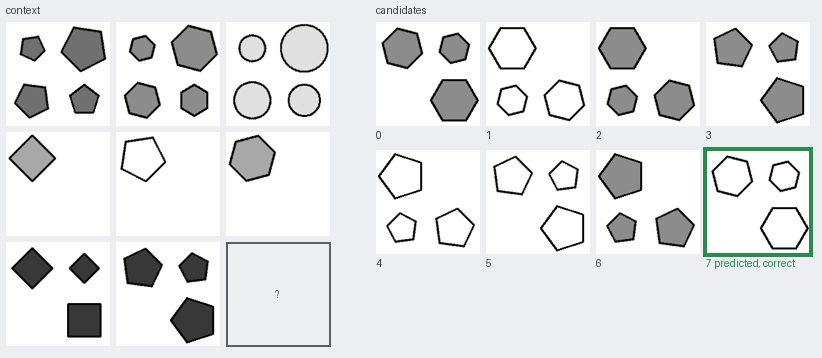

In [12]:
tmp = tempfile.mkdtemp()                                   # live run: copy the pair before reading
for n in ("model_best.pt", "template_best.bin"): shutil.copy(f"experiments/max_data_L2/{n}", tmp)
ck = torch.load(f"{tmp}/model_best.pt", map_location="cpu", weights_only=False)
assert ck["torch_state"]["perm"].tolist() == model.perm.tolist()
model.load_state_dict(ck["torch_state"]); model.nl.model.load(f"{tmp}/template_best.bin"); model.eval()
a_ = ck["args"]
print(f"epoch {ck['epoch']} | val {100 * ck['val_acc']:.2f}% | {a_['n_train']}/constellation, dim {a_['hidden_dim']}, {a_['layers']} layers")
with torch.no_grad():
    p = torch.softmax(model(attrs, active), 0)
    pred_xml = int(model(*encode_puzzle(truth, CFG)).argmax())
pred = int(p.argmax())
print("end to end, p(candidate) %:", (100 * p).numpy().round(1), "| predicted", pred, "| with XML labels", pred_xml, "| answer", target)
show_puzzle(images, {target: ((40, 140, 80), "predicted, correct")} if pred == target else
                    {target: ((40, 140, 80), "correct"), pred: ((200, 60, 60), "predicted")})

In [13]:
import train_all_constellations as T
ref = T.AllConstellations(2, 128, 128, 3, Transformation.LEAKY_RELU, 1e-4, agg=Aggregation.AVG, same_panel=False, layout="off")
ref.load_state_dict(ck["torch_state"]); ref.nl.model.load(f"{tmp}/template_best.bin"); ref.eval()
check = load(CONSTELLATIONS, "val", 2, start=300)
with torch.no_grad():
    diff = max((model(a, m) - ref(a, m)).abs().max().item() for _, a, m, _ in check)
print(f"max |inline - train_all_constellations| over {len(check)} puzzles: {diff:.2e}")
assert diff < 1e-5

max |inline - train_all_constellations| over 14 puzzles: 0.00e+00


## 10. Accuracy on unseen validation puzzles, end to end and with XML labels

In [14]:
N = 50
pix, xml = Counter(), Counter()
for cfg in CONSTELLATIONS:
    for fp in sorted(glob.glob(f"{DATA}/{cfg}/*_val.npz"))[300:300 + N]:
        z = np.load(fp); y = int(z["target"])
        with torch.no_grad():
            pix[cfg] += int(model(*encode_puzzle(perceive(z["image"], cfg), cfg)).argmax()) == y
            xml[cfg] += int(model(*encode_puzzle(parse(fp.replace(".npz", ".xml"), cfg), cfg)).argmax()) == y
print(f"{'':<40} {'end to end':>11} {'XML labels':>11}")
for cfg in CONSTELLATIONS: print(f"{cfg:<40} {100 * pix[cfg] / N:10.1f}% {100 * xml[cfg] / N:10.1f}%")
n = N * len(CONSTELLATIONS)
print(f"{'overall':<40} {100 * sum(pix.values()) / n:10.1f}% {100 * sum(xml.values()) / n:10.1f}%   (chance 12.5%, {N}/constellation)")

                                          end to end  XML labels
center_single                                  84.0%       84.0%
distribute_four                                44.0%       44.0%
distribute_nine                                28.0%       30.0%
left_center_single_right_center_single         90.0%       90.0%
up_center_single_down_center_single            82.0%       82.0%
in_center_single_out_center_single             92.0%       92.0%
in_distribute_four_out_center_single           44.0%       40.0%
overall                                        66.3%       66.0%   (chance 12.5%, 50/constellation)


## Summary

| | |
|---|---|
| perception | ResNet-18 per panel → cosine vs frozen codebook (22 positions × 300 attribute rows) → object if > 0.23 |
| input | 5 ids per slot → 5 torch embeddings, summed (`absent` for empty slots) → Linear + LayerNorm + ReLU, 128-d |
| graph | 144 slot nodes; 1,656 same-slot edges (context↔context, context↔candidate); grounded once |
| template | 3 × (messages + self + residual → NORM); candidate pool, context pool, combine, score; CONCAT → 8 |
| training | reasoner on XML labels, ResNet separately on RAVEN attribute labels; softmax cross-entropy in torch; AdamW 1e-3 on torch weights every 8 puzzles; Adam 1e-4 on template weights inside every backward |
| size | 23,552 torch + 164,480 template weights |
| result | I-RAVEN test 68.46% end to end, 68.49% with XML labels (epoch 126); earlier torch GNN 68.81% (trained with the position bug) |